# State Machines and Event-Driven Systems

From a free-form `while True` loop to an explicit state machine with human-in-the-loop checkpoints and event-driven triggers, built on LangChain + LangGraph.

| Primitive | What it is | Why it is here |
|-----------|------------|----------------|
| `TypedDict` | Typed workflow state container | One serialisable object the checkpointer can persist |
| `StateGraph` | LangGraph state-machine container | Wires nodes, edges, and conditional routes |
| `InMemorySaver` | LangGraph in-process checkpointer | Lets the graph pause and resume on the same `thread_id` |
| `EventBus` | Tiny in-memory pub/sub | Wakes the graph from external events instead of polling |

The pedagogy of this notebook is contrast: a naive **free-form** loop first, then the same workflow re-expressed as an explicit state machine with a **human-in-the-loop** checkpoint and an **event-driven** trigger. The graph never decides next-state directly, a router function does, and the checkpointer is what makes pause/resume survive across calls.

## Setup

Let's wire the model-agnostic stack and define the domain we will model.

Now, we will
- import the stdlib pieces we need for the state machine (`Enum`, `TypedDict`, `dataclass`),
- introduce a small support-ticket workflow as the running example for the rest of the notebook.

In [39]:
# !pip install -q langchain langchain-google-genai langchain-openai langchain-anthropic langgraph

from langchain.chat_models import init_chat_model
from langchain.embeddings import init_embeddings
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from typing import TypedDict, List, Optional, Callable, Dict
from enum import Enum
import os, json

from dotenv import load_dotenv
load_dotenv()

True

In [40]:
# os.environ['GEMINI_API_KEY']  # the variable for API key

# llm   = init_chat_model('gpt-4o', model_provider='openai', temperature=0)
llm   = init_chat_model('gemini-3.5-flash', model_provider='google_genai', temperature=0)

The running example for the rest of the notebook is a **support-ticket workflow**: a ticket arrives, the agent plans a response, a human approves high-risk plans, and the agent then executes. That domain has all four ingredients we want to teach — explicit states, transitions, a HITL checkpoint, and external events that wake the workflow.

In [41]:
# A toy ticket the rest of the notebook will route through every variant.
SAMPLE_TICKET = {
    'ticket_id': 'tkt-001',
    'subject':   'Refund request for damaged shipment',
    'body':      'My order arrived broken; please refund $89.',
}
print('Sample ticket:', SAMPLE_TICKET['ticket_id'], '-', SAMPLE_TICKET['subject'])

Sample ticket: tkt-001 - Refund request for damaged shipment


## The free-form loop baseline

Let's start with the shape most first-draft agents take: a `while True: think_act()` loop. We will see why it is hard to interrupt, inspect, and resume — and that failure is what motivates the state machine.

Now, we will
- implement `naive_agent_loop(ticket)` as a plain `while True` block with an in-function step counter,
- run it once on `SAMPLE_TICKET` and print what it produced,
- narrate exactly which properties the loop lacks (no named states, no pause point, no resume handle, no audit trail).

In [42]:
def get_text(msg):
    c = msg.content
    if isinstance(c, list):
        return "".join(b.get("text", "") for b in c if isinstance(b, dict) and b.get("type") == "text")
    return c

In [43]:
from typing import List

MAX_STEPS = 4

def get_text(msg):
    """Normalize an LLM response (or already-unwrapped content) into a plain string."""
    c = msg.content if hasattr(msg, "content") else msg
    if isinstance(c, list):
        return "".join(b.get("text", "") for b in c if isinstance(b, dict) and b.get("type") == "text")
    return c

def naive_agent_loop(ticket: dict) -> dict:
    """Free-form `while True` agent. No explicit states, no checkpoint, no external pause.
    The whole control flow is hidden inside the loop body, which is exactly what we are about to fix."""
    step = 0
    plan = ''
    result = ''
    trace: List[str] = []
    while True:
        step += 1
        if step == 1:
            plan = get_text(llm.invoke(f"Plan a one-line response to: {ticket['body']}"))
            trace.append(f'step{step}:plan={plan[:60]}...')
        elif step == 2:
            result = f'auto-replied: {plan[:40]}...'
            trace.append(f'step{step}:execute={result[:60]}...')
        if step >= MAX_STEPS or result:
            break
    return {'plan': plan, 'result': result, 'trace': trace}

naive_out = naive_agent_loop(SAMPLE_TICKET)

print('==== NAIVE LOOP OUTPUT ====')
print('plan  :', naive_out['plan'][:120] + '...')
print('result:', naive_out['result'][:120] + '...')
for line in naive_out['trace']:
    print(' ', line)

GoogleRateLimitError: Error calling model 'gemini-3.5-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.5-flash\nPlease retry in 15.814446338s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerDayPerProjectPerModel-FreeTier', '

In [ ]:
print(SAMPLE_TICKET)
x = llm.invoke(f"Plan a one-line response to: {SAMPLE_TICKET['body']}")
print(x)
print(x.content[0]["text"])

{'ticket_id': 'tkt-001', 'subject': 'Refund request for damaged shipment', 'body': 'My order arrived broken; please refund $89.'}
content=[{'type': 'text', 'text': '"I am so sorry your order arrived damaged; I have processed your $89 refund, and it will appear in your account within 3 to 5 business days."', 'extras': {'signature': 'EtAMCs0MAWkUfRMzQsg9ycnT13vRVqcTweKfHPW2K/6s5GAMBMEuW/Mo2p0GCT/dCRgknAq7tfYti6O6+v11cskFdyMFhjRWxejDuXAU49tCuOIN8EG3ZQtMcw+zFx8X6o+FNo3euR1plRAz0I3JuBTCknLVRNUWJP8FkWOdbkOYKj290riQakGe9JjiTg/kWjh+LCyuwMqa/hC38oqbHjhd2OoNEXSaoGd11B/bq7APp6dLvPLxRLvvTiuF5nnQai7cG4tqXHGRP9Cd28j2iq26I0Qqs0cnopAyWmODMA6hJqunSgwLE1zD0S7rLNOofKlnhblq4AimFwsUqtoCWgHCBluJvxCkzDilEmJGRta9bw7aeN3cNyLd56+DUAE5PSJmGF+bYvpRCCFrT9W0Oj5Cpob3zwRDWpsMp9L34d2X7srUaIPv2vfeczIX/YdPv17isEwUAwDVABp0QqkEAB5q+KIzCOcZUgzDpLhvV6ZGTbYhHJMrIccwWUKzU+x8MpmHDnD29nf2ZHG9uniN7VY2jMTnW8LRFtnuJKVvwf5LmQwRZOG/yv5KT/3s7FFXjoxlEgcxBc+HE2zQUYdePtNemq0Ra66844nto96tSY4VJ9wGyuL3Gm9TLVG4ICDeHiQqhsx78H2ATBs9EdlIV6VrGb

Look at what is missing. The loop has **no named states** — `step == 1` is just a magic number. There is **no pause point**: if a human needs to approve the plan, the loop has nowhere to stop. There is **no resume handle**: if the process dies between `step 1` and `step 2`, the work restarts from scratch. And there is **no audit trail** beyond what the function happens to print. Every one of those is a state-machine property — and the next section gives them to us by name.

## States as an Enum

Now let's name every state explicitly. An `Enum` makes the closed set of legal states **machine-readable** — and any transition function can be type-checked against it.

Now, we will
- define `TicketState` as an `Enum` with members `RECEIVED`, `PLANNING`, `AWAITING_HUMAN`, `EXECUTING`, `DONE`, `FAILED`,
- print the enum members so the closed set is visible at a glance,
- explain why an Enum beats string constants for routing decisions.

In [ ]:
class Plain(Enum):
    A = 'A'

print(Plain.A == 'A' )       # False!
print(f"{Plain.A}")           # 'Plain.A' (ugly)
#json.dumps(Plain.A)    # TypeError

False
Plain.A


In [ ]:
class Plain(str, Enum):
    A = 'A'

print(Plain.A == 'A' )       # False!
print(f"{Plain.A}")           # 'Plain.A' (ugly)


True
Plain.A


In [ ]:
json.dumps(Plain.A)   

'"A"'

In [ ]:
# The closed set of legal states. Using `from enum import Enum` keeps the
# state space MACHINE-READABLE: any router that branches on `state.state`
# can be exhaustively checked against TicketState members.
class TicketState(str, Enum):
    RECEIVED       = 'RECEIVED'
    PLANNING       = 'PLANNING'
    AWAITING_HUMAN = 'AWAITING_HUMAN'
    EXECUTING      = 'EXECUTING'
    DONE           = 'DONE'
    FAILED         = 'FAILED'

print('==== TicketState members ====')
for s in TicketState:
    print(f'  - {s.name}')

==== TicketState members ====
  - RECEIVED
  - PLANNING
  - AWAITING_HUMAN
  - EXECUTING
  - DONE
  - FAILED


In [ ]:
TicketState.PLANNING == 'PLANNING'   # True
f"{TicketState.PLANNING}"             # 'PLANNING' (clean)
json.dumps(TicketState.PLANNING)      # works — it's a real string
isinstance(TicketState.PLANNING, str) # True

True

Subclassing `str, Enum` keeps each member JSON-serialisable, which matters once the checkpointer starts persisting state across processes. *Tip: route on `state.state == TicketState.AWAITING_HUMAN`, never on the raw string `'AWAITING_HUMAN'`. The Enum gives us autocomplete plus a typo at the wrong layer (a missing member) becomes an `AttributeError` instead of a silently-mis-routed branch.*

## Modelling the workflow as a TypedDict and nodes

Now let's model the workflow's data and transitions explicitly. The state lives in a `TypedDict`; each transition is a small `_node` function returning the fields that change.

Now, we will
- define `WorkflowState` (a `TypedDict`) carrying `state`, `ticket_id`, `plan`, `human_decision`, `result`, `trace`,
- write `plan_node`, `await_human_node`, and `execute_node` — one transition per cell-block,
- write `route_after_plan` and `route_after_human` as PURE conditional-edge routers,
- print the seed state we will feed the graph.

In [ ]:
# WorkflowState is the SINGLE serialisable object the checkpointer will persist.
# Spreading state across module-level variables defeats the checkpointer.
class WorkflowState(TypedDict, total=False):
    state:          TicketState
    ticket_id:      str
    plan:           str
    human_decision: Optional[str]   # 'approve' | 'reject' | None
    result:         str
    trace:          List[str]

print('WorkflowState fields:', list(WorkflowState.__annotations__.keys()))

WorkflowState fields: ['state', 'ticket_id', 'plan', 'human_decision', 'result', 'trace']


A single `TypedDict` keeps every node's inputs and outputs together. That is the contract the checkpointer needs: serialise the whole state at every step, rehydrate it on resume.

In [ ]:
def extract_text(content) -> str:
    if isinstance(content, str):
        return content
    return ''.join(b.get('text', '') for b in content if isinstance(b, dict) and b.get('type') == 'text')


In [ ]:
PLAN_PROMPT = """You are a support-ticket agent. Plan a single concrete action for this ticket.

Ticket: {body}

Return one short sentence describing what to do.
"""

def plan_node(state: WorkflowState) -> dict:
    """Transition: PLANNING -> AWAITING_HUMAN. The LLM proposes a plan;
    we always route to the human checkpoint next so the operator can approve."""
    plan = extract_text(llm.invoke(PLAN_PROMPT.format(body=SAMPLE_TICKET['body'])).content)
    print("========== plan node ===========")
    print(plan)
    print("===============================")
    trace = state.get('trace', []) + [f'plan_node:plan={plan[:60]}...']
    return {'state': TicketState.AWAITING_HUMAN, 'plan': plan, 'trace': trace}

`plan_node` does the LLM call AND sets `state` to `AWAITING_HUMAN` in the returned partial. That single field is what the router will read to decide the next edge.

In [ ]:
def await_human_node(state: WorkflowState) -> dict:
    """Transition target: the graph parks here. The node body is intentionally a no-op -
    the actual pause is enforced by `interrupt_before=['await_human']` on graph.compile,
    which checkpoints the state and returns control to the caller."""
    trace = state.get('trace', []) + ['await_human_node:parked']
    return {'state': TicketState.AWAITING_HUMAN, 'trace': trace}

The pause is not implemented inside the node — it is declared at compile time. Putting the pause in the *graph configuration* (not the node body) means the same node can be unit-tested without any HITL machinery.

In [ ]:
def execute_node(state: WorkflowState) -> dict:
    """Transition: EXECUTING -> DONE (or FAILED). When the human rejects we mark the ticket FAILED;
    when approved we mark it DONE with a synthetic result so the demo is fully deterministic."""
    decision = state.get('human_decision')
    if decision == 'reject':
        result = 'rejected by reviewer; no action taken'
        end_state = TicketState.FAILED
    else:
        result = f"executed plan: {state.get('plan', '')[:40]}..."
        end_state = TicketState.DONE
    trace = state.get('trace', []) + [f'execute_node:end={end_state.name}']
    return {'state': end_state, 'result': result, 'trace': trace}

And the routers — pure functions that read state and return a node name. Keeping routing OUT of node bodies is the FSM discipline: nodes mutate data, routers decide control flow.

In [ ]:
def route_after_plan(state: WorkflowState) -> str:
    """After PLANNING we always need human approval, so route unconditionally to await_human."""
    return 'await_human'

def route_after_human(state: WorkflowState) -> str:
    """After the human verdict, route to execute (which itself maps approve->DONE, reject->FAILED)."""
    return 'execute'

seed_state: WorkflowState = {
    'state':          TicketState.RECEIVED,
    'ticket_id':      SAMPLE_TICKET['ticket_id'],
    'plan':           '',
    'human_decision': None,
    'result':         '',
    'trace':          [],
}
print('==== seed state ====')
print(json.dumps({k: (v.name if hasattr(v, 'name') else v) for k, v in seed_state.items()}, indent=2))

==== seed state ====
{
  "state": "RECEIVED",
  "ticket_id": "tkt-001",
  "plan": "",
  "human_decision": null,
  "result": "",
  "trace": []
}


## Wiring the StateGraph with InMemorySaver

Now let's compose the nodes into a `StateGraph` and bind a checkpointer so the graph can pause and resume on the same `thread_id`.

Now, we will
- build a `StateGraph(WorkflowState)` and add `plan`, `await_human`, `execute` as nodes,
- add `START -> plan` and the two conditional edges (`plan -> await_human`, `await_human -> execute`),
- compile with `interrupt_before=['await_human']` so the graph stops at the HITL checkpoint,
- attach an `InMemorySaver()` so paused state is persisted and reusable on the next invoke,
- print the compiled node list.

In [ ]:
# StateGraph wiring. The checkpointer is what makes pause/resume work -
# without it, interrupt_before would have nothing to persist.
builder = StateGraph(WorkflowState)
builder.add_node('plan',        plan_node)
builder.add_node('await_human', await_human_node)
builder.add_node('execute',     execute_node)

builder.add_edge(START, 'plan')
builder.add_conditional_edges('plan',        route_after_plan,  {'await_human': 'await_human'})
builder.add_conditional_edges('await_human', route_after_human, {'execute':     'execute'})
builder.add_edge('execute', END)

# InMemorySaver is in-process. In production swap to SqliteSaver / PostgresSaver
# so checkpoints survive process restarts and scale out across workers.
checkpointer = InMemorySaver()

# `interrupt_before` is the LangGraph API we are using here. It pauses the graph
# BEFORE the named node runs, persists state via the checkpointer, and returns
# control to the caller. Some LangGraph versions also expose an `interrupt()`
# primitive that lives inside a node body - we prefer interrupt_before because
# the pause is declared at compile time rather than buried in node code.
graph = builder.compile(checkpointer=checkpointer, interrupt_before=['await_human'])

print('==== compiled graph ====')
print('nodes:', list(builder.nodes.keys()))

==== compiled graph ====
nodes: ['plan', 'await_human', 'execute']


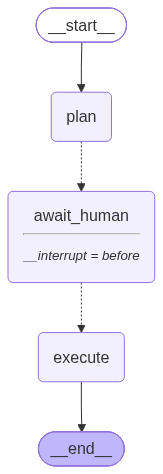

In [ ]:
graph

Note: `interrupt_before=['await_human']` is the version of the LangGraph pause API we picked. The alternative is calling `interrupt(payload)` from inside a node body — same outcome, but the compile-time form keeps the node body free of HITL plumbing.

## Human-in-the-loop pause and resume

Now let's actually exercise the pause. We invoke the graph once, watch it stop at `AWAITING_HUMAN`, inspect the persisted state, then re-invoke with the operator's verdict.

Now, we will
- invoke `graph` with the seed state under a stable `thread_id`,
- show the graph paused at `await_human` and print the persisted `state` and `plan`,
- update the checkpoint with `human_decision='approve'` and re-invoke the same `thread_id` to resume,
- print the final state, the result, and the full trace.

In [47]:
# The thread_id is the continuation handle. Same id = same paused workflow.
config = {'configurable': {'thread_id': 'tkt-001-thread'}}
snapshot = graph.get_state(config)

if not snapshot.values:
    print("no checkpoint yet — invoke the graph first")
elif snapshot.next:
    print(f"going to execute: {snapshot.next[0]}")
else:
    print("graph has finished — nothing pending")




Deserializing unregistered type __main__.TicketState from checkpoint. This will be blocked in a future version. Set LANGGRAPH_STRICT_MSGPACK=true to block now, or add to allowed_msgpack_modules to allow explicitly: [('__main__', 'TicketState')]


going to execute: plan


In [45]:
print(snapshot.values)

{}


In [48]:
# confirm checkpointer object identity hasn't changed
print(id(checkpointer))

# re-run invoke fresh, then immediately check
first_pass = graph.invoke(seed_state, config=config)
snapshot = graph.get_state(config)
print(snapshot.values)   # should be non-empty now
print(snapshot.next)     # should show ('await_human',)

138501289299280
========== plan node ===========
Process an $89 refund to the customer's original payment method for the damaged item.
{'state': <TicketState.AWAITING_HUMAN: 'AWAITING_HUMAN'>, 'ticket_id': 'tkt-001', 'plan': "Process an $89 refund to the customer's original payment method for the damaged item.", 'human_decision': None, 'result': '', 'trace': ["plan_node:plan=Process an $89 refund to the customer's original payment met..."]}
('await_human',)


In [49]:
print(snapshot.values)

{'state': <TicketState.AWAITING_HUMAN: 'AWAITING_HUMAN'>, 'ticket_id': 'tkt-001', 'plan': "Process an $89 refund to the customer's original payment method for the damaged item.", 'human_decision': None, 'result': '', 'trace': ["plan_node:plan=Process an $89 refund to the customer's original payment met..."]}


In [50]:
print('==== FIRST INVOKE (expect pause at await_human) ====')
print('state field    :', first_pass.get('state'))
print('plan           :', (first_pass.get('plan') or '')[:120] + '...')
# snapshot = graph.get_state(config)
# print('next pending   :', snapshot.next)
# print('paused?        :', bool(snapshot.next))

==== FIRST INVOKE (expect pause at await_human) ====
state field    : TicketState.AWAITING_HUMAN
plan           : Process an $89 refund to the customer's original payment method for the damaged item....


The invoke returned **before** `await_human` ran. `snapshot.next` shows the node the runtime is parked in front of, and the persisted state still has `state == AWAITING_HUMAN` from the `plan_node` transition. Now we deliver the operator's verdict by updating the checkpoint and re-invoking the same `thread_id`.

In [51]:
# Operator delivers a verdict. We write it onto the persisted state and
# re-invoke with input=None so LangGraph picks up exactly where it paused.
graph.update_state(config, {'human_decision': 'approve'})
second_pass = graph.invoke(None, config=config)

print('==== SECOND INVOKE (resume after approve) ====')
print('state field    :', second_pass.get('state'))
print('result         :', (second_pass.get('result') or '')[:120] + '...')
print('---- TRACE ----')
for line in second_pass.get('trace', []):
    print(' ', line)

==== SECOND INVOKE (resume after approve) ====
state field    : TicketState.DONE
result         : executed plan: Process an $89 refund to the customer's ......
---- TRACE ----
  plan_node:plan=Process an $89 refund to the customer's original payment met...
  await_human_node:parked
  execute_node:end=DONE


*Tip: to pause without `interrupt_before`, you can call `interrupt(payload)` inside the node body. Either way, the contract is the same — the checkpointer persists, the `thread_id` is the resume handle, and the next `invoke` continues from the pause.*

## Event-driven triggers with an EventBus

Now let's stop polling and let external events drive the workflow. A tiny in-memory `EventBus` (publish/subscribe) wakes the graph on `NEW_TICKET`, `APPROVAL_GRANTED`, and `TIMEOUT_FIRED`.

Now, we will
- implement `EventBus` with `subscribe(event_name, handler)` and `publish(event_name, payload)` (a dict-of-lists; subscribers run synchronously in subscription order),
- subscribe three handlers wired to the graph: `NEW_TICKET` -> start, `APPROVAL_GRANTED` -> resume, `TIMEOUT_FIRED` -> mark FAILED,
- publish a `NEW_TICKET` event, observe the pause, then publish `APPROVAL_GRANTED` and watch the workflow finish,
- print the full trace under `=== TRACE ===`.

In [53]:
# A minimal synchronous pub/sub. Subscribers are dispatched in subscription
# order, on the publishing thread - that determinism is what makes the demo
# easy to read; a real bus would use a queue + worker pool.
class EventBus:
    """Tiny in-memory publish/subscribe broker. Synchronous, in-order dispatch."""
    def __init__(self) -> None:
        self._subs: Dict[str, List[Callable[[dict], None]]] = {}

    def subscribe(self, event_name: str, handler: Callable[[dict], None]) -> None:
        """Register a handler for an event name. Multiple subscribers are allowed and run in order."""
        self._subs.setdefault(event_name, []).append(handler)

    def publish(self, event_name: str, payload: dict) -> None:
        """Dispatch payload to every subscriber of event_name, synchronously, in subscription order."""
        for handler in self._subs.get(event_name, []):
            handler(payload)

bus = EventBus()
print('EventBus ready:', bus.__class__.__name__)

EventBus ready: EventBus


Now the three handlers. Each one is a thin adapter from an event payload to a graph operation — no business logic, just routing. The graph remains the single source of truth for state.

In [ ]:
# Shared mutable used by the event handlers so we can inspect the result
# after the bus has dispatched. In production this would be a database row.
EVENT_LOG: List[str] = []
FINAL_OUT: Dict[str, dict] = {}

def on_new_ticket(payload: dict) -> None:
    """Wake the graph for a brand new ticket. Pauses at AWAITING_HUMAN."""
    EVENT_LOG.append(f"NEW_TICKET:{payload['ticket_id']}")
    cfg = {'configurable': {'thread_id': payload['ticket_id'] + '-bus'}}
    seed: WorkflowState = {
        'state':          TicketState.RECEIVED,
        'ticket_id':      payload['ticket_id'],
        'plan':           '',
        'human_decision': None,
        'result':         '',
        'trace':          [],
    }
    out = graph.invoke(seed, config=cfg)
    FINAL_OUT[payload['ticket_id']] = out

def on_approval_granted(payload: dict) -> None:
    """Resume the paused graph with an approve verdict."""
    EVENT_LOG.append(f"APPROVAL_GRANTED:{payload['ticket_id']}")
    cfg = {'configurable': {'thread_id': payload['ticket_id'] + '-bus'}}
    graph.update_state(cfg, {'human_decision': 'approve'})
    out = graph.invoke(None, config=cfg)
    FINAL_OUT[payload['ticket_id']] = out

def on_timeout_fired(payload: dict) -> None:
    """Operator never responded - flip the persisted state to FAILED."""
    EVENT_LOG.append(f"TIMEOUT_FIRED:{payload['ticket_id']}")
    cfg = {'configurable': {'thread_id': payload['ticket_id'] + '-bus'}}
    graph.update_state(cfg, {'state': TicketState.FAILED, 'result': 'timeout: no human verdict'})

bus.subscribe('NEW_TICKET',        on_new_ticket)
bus.subscribe('APPROVAL_GRANTED',  on_approval_granted)
bus.subscribe('TIMEOUT_FIRED',     on_timeout_fired)
print('subscriptions:', list(bus._subs.keys()))

Three subscriptions, three event types. The graph is now reachable through the bus — nothing else in the rest of this demo touches `graph.invoke` directly. That is the entire point of the **event-driven** style: the graph reacts; nobody polls.

In [ ]:
# Drive the demo: NEW_TICKET wakes the graph -> pause at AWAITING_HUMAN ->
# APPROVAL_GRANTED resumes -> EXECUTING -> DONE.
bus.publish('NEW_TICKET', {'ticket_id': 'tkt-bus-1', 'body': SAMPLE_TICKET['body']})

paused_snap = graph.get_state({'configurable': {'thread_id': 'tkt-bus-1-bus'}})
print('---- after NEW_TICKET ----')
print('next pending :', paused_snap.next)
print('state        :', paused_snap.values.get('state'))
print('plan         :', (paused_snap.values.get('plan') or '')[:120] + '...')

bus.publish('APPROVAL_GRANTED', {'ticket_id': 'tkt-bus-1'})

final = FINAL_OUT['tkt-bus-1']
print('---- after APPROVAL_GRANTED ----')
print('state        :', final.get('state'))
print('result       :', (final.get('result') or '')[:120] + '...')

print('=== TRACE ===')
for line in final.get('trace', []):
    print(' ', line)
print('event log    :', EVENT_LOG)

Two `bus.publish` calls drove the entire workflow end-to-end. The graph paused at the human checkpoint and resumed exactly when an approval event arrived — no thread sat blocked, no polling loop spun. That is what **event-driven** with a checkpointed state machine buys.

### Adopting state machines and HITL in production
- Keep the state set small and named with an `Enum` — every transition function should be exhaustively checkable against the enum members; a missing case becomes a routing bug at compile time, not a 3am page.
- Swap `InMemorySaver` for `SqliteSaver` (or `PostgresSaver`) before deploy. The interface is identical; loss of paused state on restart is a development convenience, not a production property.
- Always set `recursion_limit` on `StateGraph.invoke`. Even with explicit states, a buggy router can cycle forever — bound it per-graph and never higher than your cost budget allows.
- Persist the `thread_id` with the ticket row, not in memory. Resume is impossible without it; a human-in-the-loop workflow that loses its `thread_id` is just a stuck row in your database.

### Common pitfalls in event-driven agent triggers
- Synchronous dispatch is fine for a demo but blocks the publisher's thread. In production, put a queue (Redis, SQS, Kafka) between the bus and the handlers so a slow handler does not stall every other event. <br>Mitigation: keep handlers thin and offload the graph invoke to a worker.
- Subscriber order matters when handlers mutate the same state. Make ordering explicit (priority field, single subscriber per event) rather than relying on subscription order.
- Treat `TIMEOUT_FIRED` as a first-class event, not an afterthought. Without a timeout subscriber, a paused thread sits in `AWAITING_HUMAN` forever and your dashboards will not surface it. <br>Mitigation: schedule a timeout when entering `AWAITING_HUMAN`, cancel it on resume.
- Never let an LLM emit raw event names. The bus is part of your control plane; only typed wrappers (or a small command schema) should be allowed to publish.